# Example of the aitlas toolbox in the context of multi class image classification

The dataset can be used for image classification and object detection. This notebook showcases an image classification example.

## Import the required packages

In [ ]:
from aitlas.datasets import COWCMImageClassificationDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/cowc_m_image_classification/datasets/Sorted_Cars_By_Type_All/",
    "csv_file": "./data/cowc_m_image_classification/datasets/Sorted_Cars_By_Type_All/cowc_m_image_classification_train.csv",
}
dataset = COWCMImageClassificationDataset(dataset_config)
print(f"Total number of patches: {len(dataset)}")

Total number of patches: 29873


## Show images from the dataset

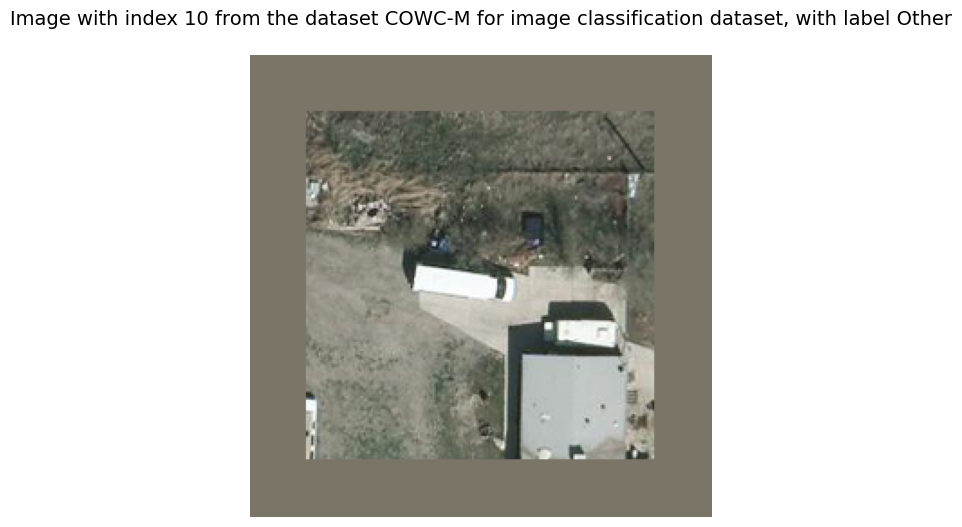

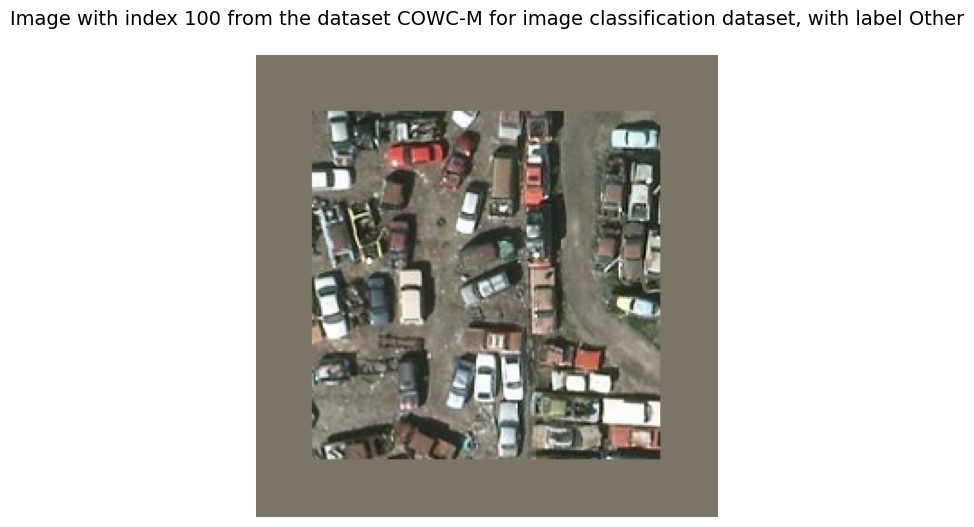

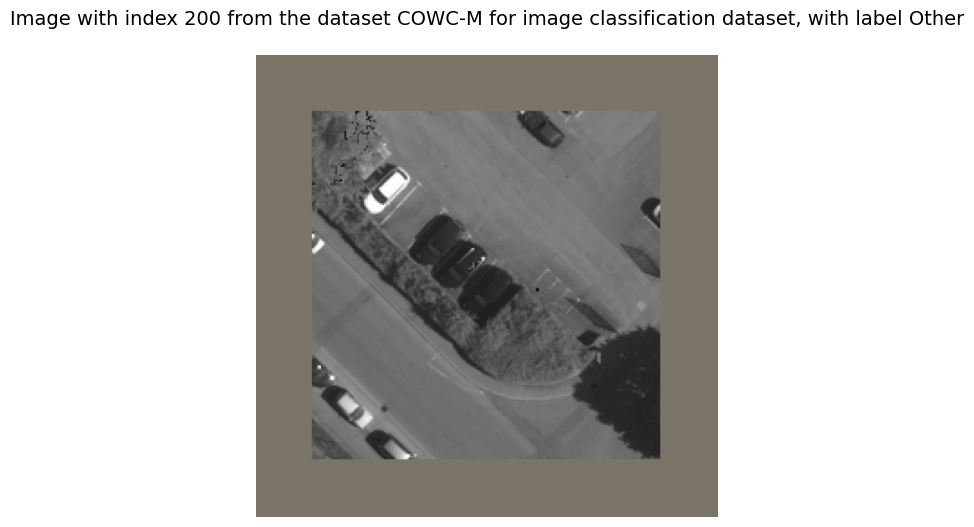

In [7]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(100)
fig3 = dataset.show_image(200);

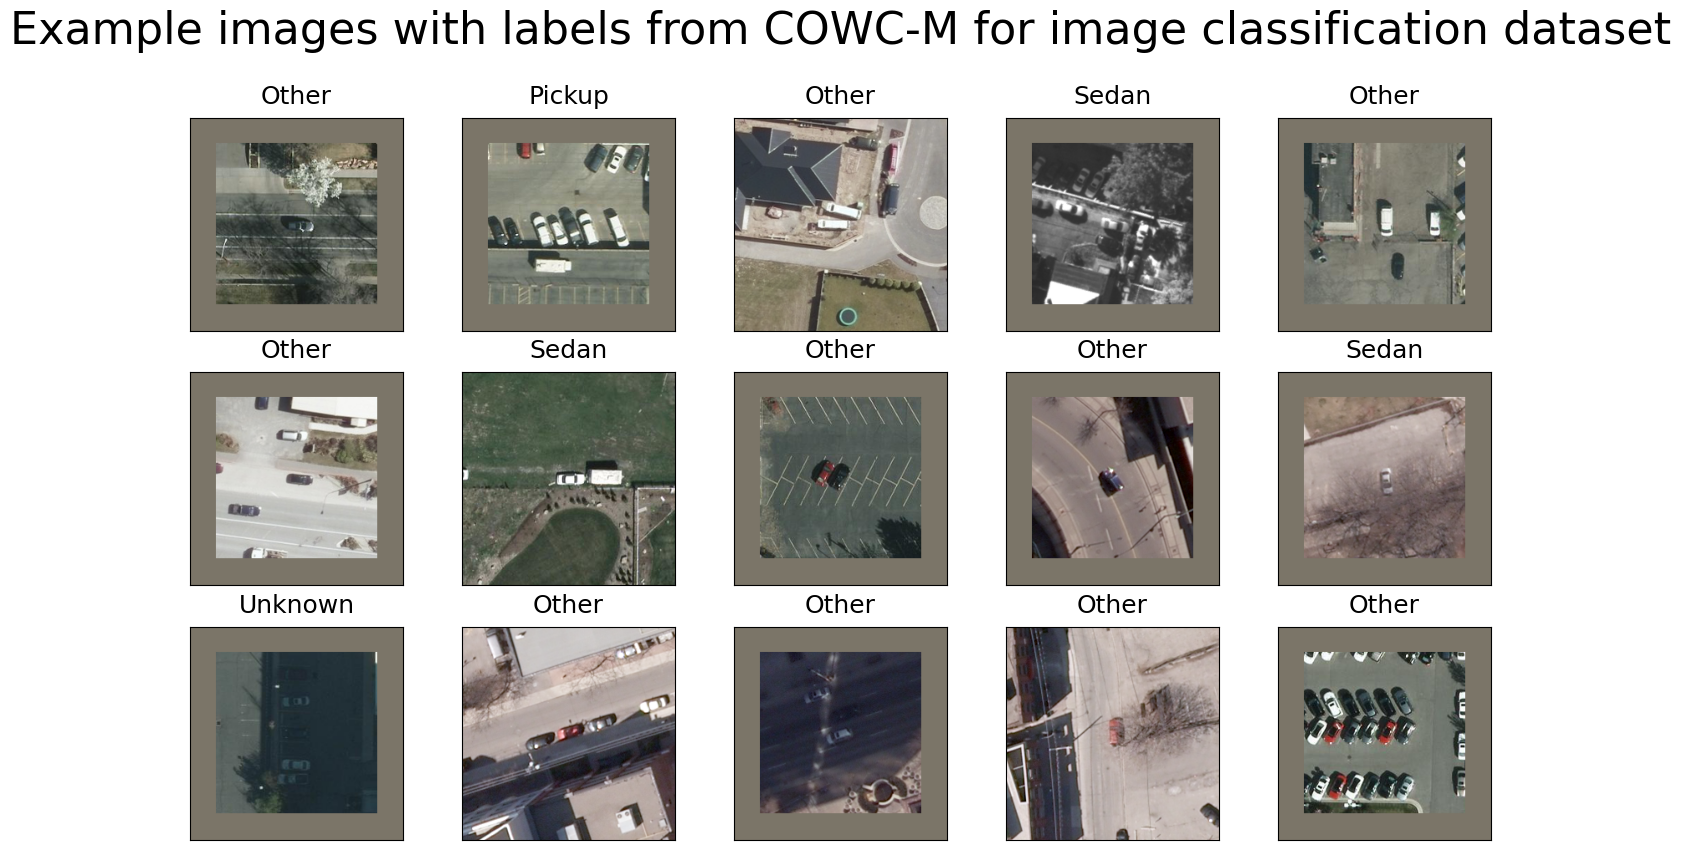

In [8]:
fig4 = dataset.show_batch(15);

## Inspect the data

In [13]:
dataset.show_samples()

,File_name,Label
0,Utah_AGRC/Pickup/car.Utah_AGRC-HRO_15.0cm_12TV...,Pickup
1,Toronto_ISPRS/Sedan/car.Toronto_03559.03514.06...,Sedan
2,Utah_AGRC/Sedan/car.Utah_AGRC-HRO_15.0cm_12TVL...,Sedan
3,Toronto_ISPRS/Sedan/car.Toronto_03553.04233.07...,Sedan
4,Toronto_ISPRS/Pickup/car.Toronto_03553.06544.0...,Pickup
5,Toronto_ISPRS/Sedan/car.Toronto_03559.09867.03...,Sedan
6,Potsdam_ISPRS/Other/car.Potsdam_4_10_RGB.01466...,Other
7,Toronto_ISPRS/Other/car.Toronto_03747.01760.06...,Other
8,Toronto_ISPRS/Sedan/car.Toronto_03559.01369.01...,Sedan
9,Utah_AGRC/Unknown/car.Utah_AGRC-HRO_15.0cm_12T...,Unknown


In [17]:
dataset.data_distribution_table()

,Label,Count
0,Sedan,12725
1,Pickup,2291
2,Other,12382
3,Unknown,2476


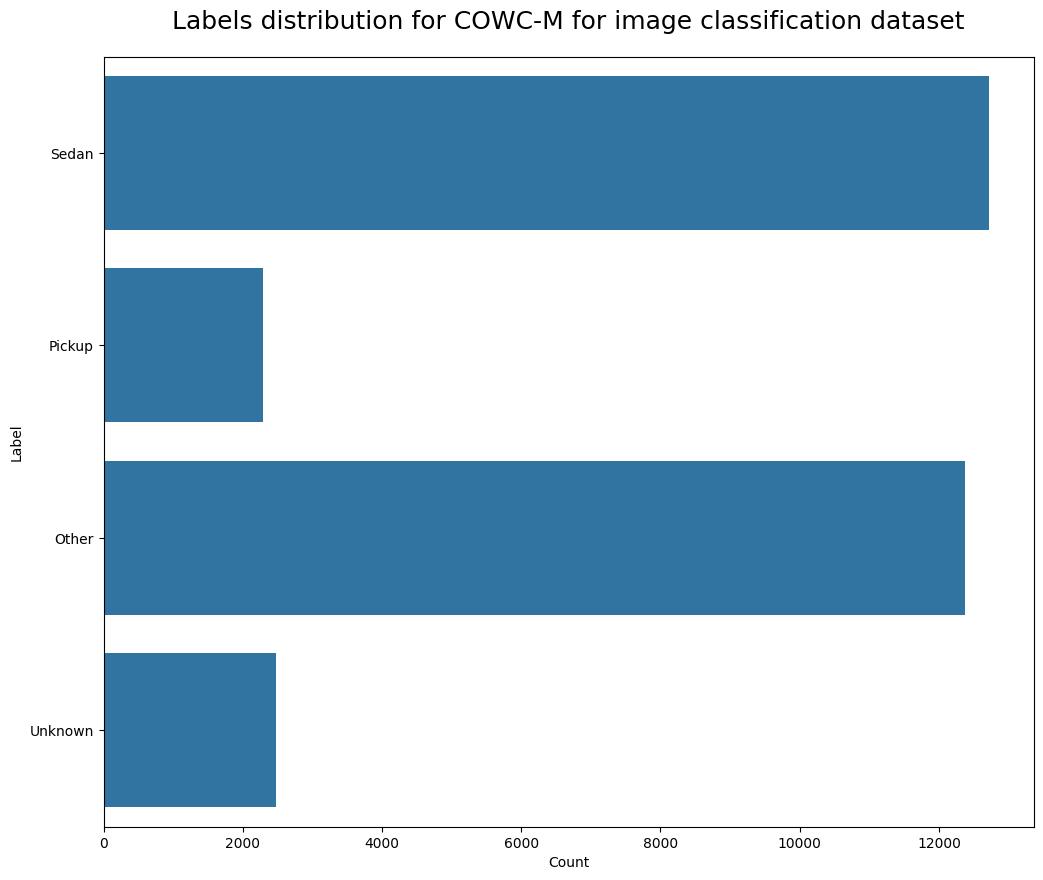

In [18]:
fig = dataset.data_distribution_barchart();

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/cowc_m_image_classification/datasets/Sorted_Cars_By_Type_All/",
    "csv_file": "./data/cowc_m_image_classification/datasets/Sorted_Cars_By_Type_All/cowc_m_image_classification_train.csv",
}

train_dataset = COWCMImageClassificationDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/cowc_m_image_classification/datasets/Sorted_Cars_By_Type_All/",
    "csv_file": "./data/cowc_m_image_classification/datasets/Sorted_Cars_By_Type_All/cowc_m_image_classification_val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = COWCMImageClassificationDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(29873, 3734)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/cowc_m_image_classification/"
model_config = {
    "num_classes": 4, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-10-30 12:45:24,422 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-10-30 12:45:24,614 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [7]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-10-30 12:45:24,686 INFO Starting training.
training: 100%|██████████| 934/934 [03:59<00:00,  3.90it/s]
2025-10-30 12:49:24,280 INFO epoch: 1, time: 240, loss:  0.93498
testing on train set: 100%|██████████| 934/934 [01:24<00:00, 11.09it/s]
2025-10-30 12:50:50,801 INFO Accuracy:0.6774344726006762, Precision Micro:0.6774344726006762, Precision Macro:0.7024490300500521, Precision Weighted:0.6870278364782416, Precision per Class:[0.63881867 0.81380208 0.72100515 0.63617021], Recall Micro:0.6774344726006762, Recall Macro:0.4834774395592913, Recall Weighted:0.6774344726006762, Recall per Class:[0.83684678 0.27280663 0.70349705 0.12075929], F1_score Micro:0.6774344726006757, F1_score Macro:0.5120765844075688, F1_score Weighted:0.6518056927389527, F1_score per Class:[0.72454545 0.40863027 0.71214351 0.2029871 ]
testing on validation set: 100%|██████████| 117/117 [00:10<00:00, 10.94it/s]
2025-10-30 12:51:01,513 INFO Accuracy:0.6636314943760043, Precision Micro:0.6636314943760043, Precision

0.6177958977520536

## Predictions

2025-10-30 13:41:40,242 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/cowc_m_image_classification/checkpoint.pth.tar
2025-10-30 13:41:40,538 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/cowc_m_image_classification/checkpoint.pth.tar at epoch 11


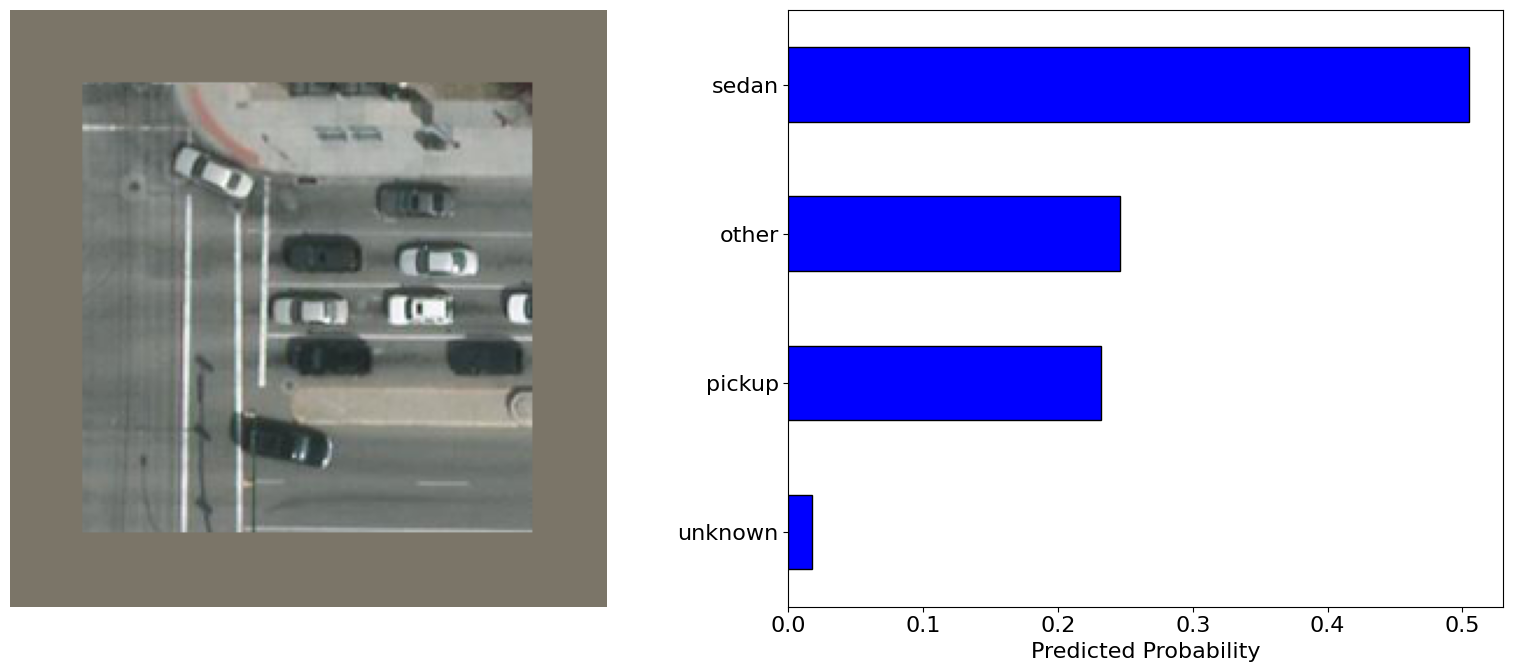

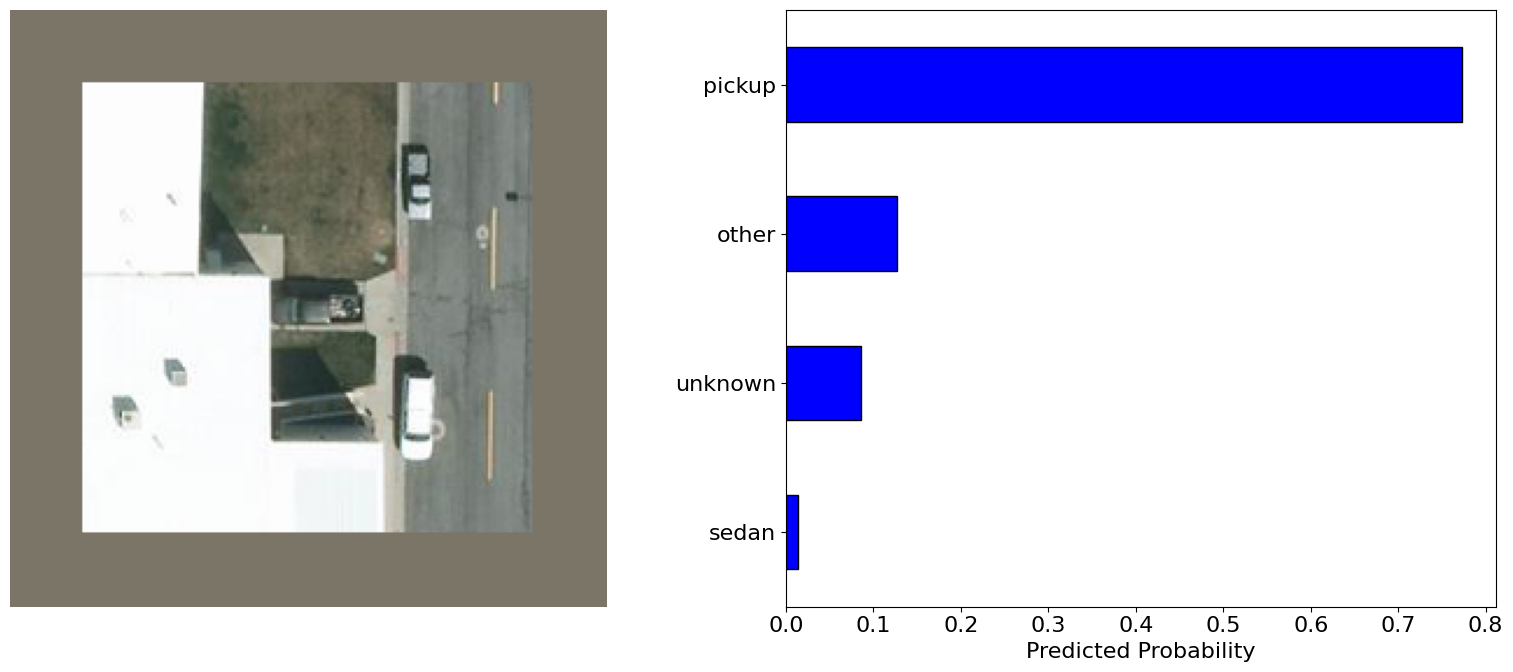

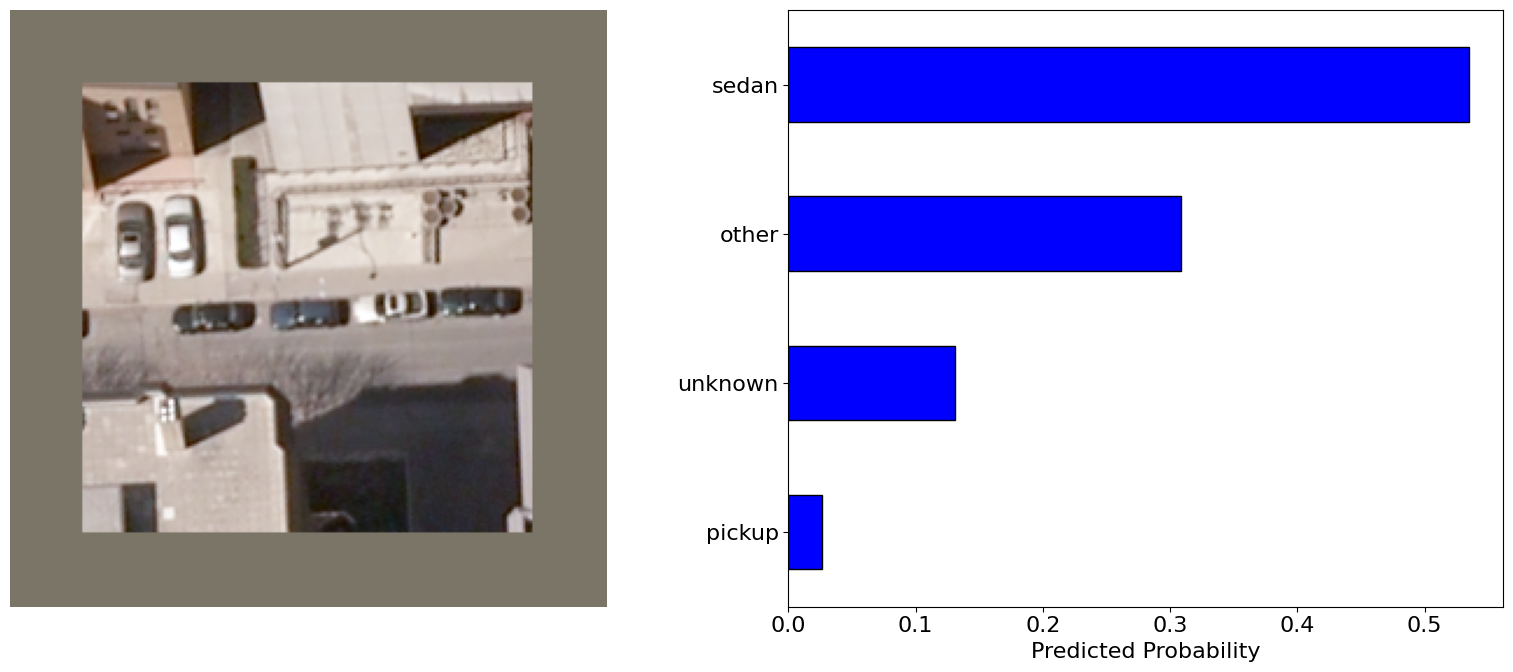

In [ ]:
labels = ["sedan","pickup","other","unknown"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/cowc_m_image_classification/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/cowc_m_image_classification/datasets/Sorted_Cars_By_Type_All/Utah_AGRC/Sedan/car.Utah_AGRC-HRO_15.0cm_12TVL240120.00659.01416.000.png')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/cowc_m_image_classification/datasets/Sorted_Cars_By_Type_All/Utah_AGRC/Pickup/car.Utah_AGRC-HRO_15.0cm_12TVL180140.07954.10017.000.png')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/cowc_m_image_classification/datasets/Sorted_Cars_By_Type_All/Toronto_ISPRS/Other/car.Toronto_03553.04158.00504.015.png')
fig = model.predict_image(image, labels, transform)